# Project 1: Exploratory Data Analysis
### Understanding, Cleaning and Profiling Retail Customer Sales Data
**Data Analyst Training Program | Mini Project, 2nd Year Engineering**

**Dataset:** `retail_customer_sales_dataset.csv` (retail transactions, 2023-2024, four regions of India)

**Workflow:** 1) Setup and first look, 2) Data-quality audit, 3) Cleaning with justification, 4) Descriptive statistics and univariate analysis, 5) Outlier detection, 6) Feature engineering and business questions, 7) Export of the cleaned dataset.

## 1. Setup and First Look

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
pd.options.display.float_format = '{:,.2f}'.format

In [2]:
df_raw = pd.read_csv('retail_customer_sales_dataset.csv')
print('Shape (rows, columns):', df_raw.shape)
print()
print(df_raw.dtypes.to_string())

Shape (rows, columns): (7084, 24)

Transaction_ID            str
Customer_ID               str
Order_Date                str
Delivery_Date             str
Age                   float64
Gender                    str
Income                float64
Region                    str
State                     str
City                      str
Customer_Segment          str
Product_Category          str
Product                   str
Quantity                int64
Unit_Price            float64
Discount              float64
Sales                 float64
Cost                  float64
Profit                float64
Payment_Method            str
Delivery_Mode             str
Customer_Rating       float64
Satisfaction_Level        str
Returned                  str


In [3]:
df_raw.head()

  Transaction_ID Customer_ID  Order_Date Delivery_Date   Age  Gender    Income Region      State      City Customer_Segment Product_Category        Product  Quantity  Unit_Price  Discount     Sales      Cost   Profit Payment_Method Delivery_Mode  Customer_Rating Satisfaction_Level Returned
0      TXN205933   CUST10816  2023-12-19    2023-12-25 38.00    Male 62,828.52   West    Gujarat     Surat         Consumer          Grocery      Honey Jar         3      887.94      0.32  1,811.40  1,204.47   606.93     Debit Card      Standard             3.00                Low       No
1      TXN201247   CUST10916  2023-09-30    2023-10-04 42.00    Male 50,952.64  North    Haryana  Gurugram      Home Office      Electronics      USB-C Hub         2   14,309.96      0.18 23,468.33 17,137.06 6,331.27    Credit Card      Standard             3.00               High       No
2      TXN202714   CUST11352  2023-01-12    2023-01-20 41.00    Male 60,476.00   East  Jharkhand    Ranchi         Consumer    

In [4]:
df_raw.tail()

     Transaction_ID Customer_ID  Order_Date Delivery_Date   Age  Gender    Income Region        State         City Customer_Segment Product_Category        Product  Quantity  Unit_Price  Discount    Sales     Cost   Profit Payment_Method Delivery_Mode  Customer_Rating Satisfaction_Level Returned
7079      TXN201768   CUST10870  2024-10-22    2024-10-27 34.00    Male 79,446.58   East       Odisha  Bhubaneswar        Corporate      Electronics   Laptop Stand         1    5,395.38      0.09 4,909.80 3,273.47 1,636.33    Net Banking       Express             2.00                Low      Yes
7080      TXN201737   CUST10314  2024-10-05    2024-10-14 50.00    Male 21,796.92   East  West Bengal     Durgapur      Home Office         Clothing   Formal Shirt         3    1,603.82      0.02 4,715.23 2,923.68 1,791.55    Credit Card      Standard             4.00               High       No
7081      TXN203240   CUST10859  2024-06-04    2024-06-15 42.00    Male 60,621.27   West      Gujarat        

## 2. Data Quality Audit
Every issue is only *detected* here. Nothing is changed until Section 3.

### 2.1 Missing values

In [5]:
miss = pd.DataFrame({'missing_count': df_raw.isna().sum(),
                     'missing_pct': (df_raw.isna().mean() * 100).round(2)})
miss[miss.missing_count > 0].sort_values('missing_count', ascending=False)

                    missing_count  missing_pct
Customer_Rating               428         6.04
Income                        253         3.57
Satisfaction_Level            179         2.53
Age                           142         2.00
Delivery_Date                 106         1.50
Discount                       71         1.00


### 2.2 Duplicate rows

In [6]:
print('Exact duplicate rows            :', df_raw.duplicated().sum())
print('Repeated Transaction_ID values   :', df_raw.Transaction_ID.duplicated().sum())

# Same Transaction_ID but rows are NOT identical -> the copies differ only in formatting
ids = df_raw[df_raw.Transaction_ID.duplicated(keep=False) & ~df_raw.duplicated(keep=False)].sort_values('Transaction_ID')
print('Rows whose ID repeats but text differs:', len(ids))
ids[['Transaction_ID', 'Order_Date', 'Gender', 'Region', 'Satisfaction_Level']].head(6)

Exact duplicate rows            : 61
Repeated Transaction_ID values   : 84
Rows whose ID repeats but text differs: 46
     Transaction_ID   Order_Date  Gender Region Satisfaction_Level
1227      TXN200162   22/07/2024  Female  South               High
1386      TXN200162   2024-07-22  Female  South               High
3392      TXN200221   2023-06-23  female   West                NaN
6761      TXN200221   2023-06-23  Female   West                NaN
3719      TXN200275   30/06/2024    Male  NORTH                NaN
2682      TXN200275  30-Jun-2024    Male  North                NaN


**Finding:** besides exact copies, some transactions are repeated with different date formats or letter casing (for example `22/07/2024` vs `2024-07-22`). These are *hidden* duplicates, so categories and dates must be standardised **before** duplicates are removed.

### 2.3 Inconsistent category labels

In [7]:
print('Gender :', df_raw.Gender.value_counts().to_dict())
print()
print('Region :', df_raw.Region.value_counts().to_dict())

Gender : {'Female': 3585, 'Male': 3232, 'FEMALE': 53, 'female': 53, 'male': 46, 'MALE': 44, 'M': 38, 'F': 33}

Region : {'West': 1783, 'East': 1754, 'South': 1741, 'North': 1647, 'east': 30, 'south': 24, 'north': 21, 'Sth': 20, 'WEST': 19, 'Nort': 17, 'west': 15, 'NORTH': 13}


### 2.4 Impossible or out-of-range numerical values

In [8]:
age_bad = df_raw[(df_raw.Age <= 0) | (df_raw.Age > 100)]
disc_bad = df_raw[(df_raw.Discount < 0) | (df_raw.Discount > 0.5)]
print('Invalid Age rows       :', len(age_bad), '->', sorted(age_bad.Age.tolist()))
print('Invalid Discount rows  :', len(disc_bad), '->', sorted(disc_bad.Discount.tolist()))
print('Income above 5 lakh    :', (df_raw.Income > 500_000).sum(), '-> top values', df_raw.Income.nlargest(3).round(0).tolist())

# Business rule from the data dictionary: Sales = Quantity x Unit_Price x (1 - Discount)
expected = df_raw.Quantity * df_raw.Unit_Price * (1 - df_raw.Discount)
mismatch = ((expected - df_raw.Sales).abs() / df_raw.Sales) > 0.05
print('Rows violating the Sales formula (>5% gap):', mismatch.sum())
print('Rows with Profit != Sales - Cost           :', ((df_raw.Sales - df_raw.Cost - df_raw.Profit).abs() > 1).sum())

Invalid Age rows       : 6 -> [-12.0, -5.0, -1.0, 150.0, 180.0, 999.0]
Invalid Discount rows  : 6 -> [-0.2, -0.1, 1.1, 1.2, 1.5, 2.0]
Income above 5 lakh    : 6 -> top values [1750890.0, 721082.0, 622290.0]
Rows violating the Sales formula (>5% gap): 6
Rows with Profit != Sales - Cost           : 0


**Finding:** the six rows that break the Sales formula are exactly the six rows with an invalid Discount. Sales itself is therefore reliable, and the Discount can be **reconstructed** from it.

### 2.5 Date formats and date logic

In [9]:
def date_format(s):
    return np.select([s.str.match(r'^\d{4}-\d{2}-\d{2}$', na=False),
                      s.str.match(r'^\d{2}/\d{2}/\d{4}$', na=False),
                      s.str.match(r'^\d{2}-[A-Za-z]{3}-\d{4}$', na=False),
                      s.str.match(r'^\d{2}-\d{2}-\d{4}$', na=False)],
                     ['YYYY-MM-DD', 'DD/MM/YYYY', 'DD-Mon-YYYY', 'MM-DD-YYYY'], default='missing')

print('Order_Date formats   :', pd.Series(date_format(df_raw.Order_Date)).value_counts().to_dict())
print('Delivery_Date formats:', pd.Series(date_format(df_raw.Delivery_Date)).value_counts().to_dict())

Order_Date formats   : {'YYYY-MM-DD': 6601, 'DD-Mon-YYYY': 161, 'DD/MM/YYYY': 161, 'MM-DD-YYYY': 161}
Delivery_Date formats: {'YYYY-MM-DD': 6509, 'DD-Mon-YYYY': 158, 'DD/MM/YYYY': 156, 'MM-DD-YYYY': 155, 'missing': 106}


Four formats are mixed. Two of them are day/month-ambiguous: `DD/MM/YYYY` (`05/03/2024` = 5 March) and `MM-DD-YYYY` (`02-21-2024` = 21 February, month first). Letting pandas guess with `format='mixed'` swaps day and month and produces delivery gaps of -260 or +275 days. In the `MM-DD-YYYY` rows the second number goes up to 31 and the first only up to 12, which is how the format is identified. Each format is therefore parsed **explicitly** in Section 3.

## 3. Data Cleaning
Each decision below states *why* the treatment was chosen. Original rows are never edited silently: every imputed value gets a flag column.

### 3.1 Standardise categories

In [10]:
df = df_raw.copy()

df['Gender'] = df.Gender.str.strip().str.title().replace({'M': 'Male', 'F': 'Female'})
df['Region'] = df.Region.str.strip().str.title().replace({'Nort': 'North', 'Sth': 'South'})

print(df.Gender.value_counts().to_dict())
print(df.Region.value_counts().to_dict())

{'Female': 3724, 'Male': 3360}
{'West': 1817, 'South': 1785, 'East': 1784, 'North': 1698}


### 3.2 Convert dates to datetime (each format parsed explicitly)

In [11]:
def parse_dates(s):
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for pattern, fmt in [(r'^\d{4}-\d{2}-\d{2}$', '%Y-%m-%d'),
                         (r'^\d{2}/\d{2}/\d{4}$', '%d/%m/%Y'),
                         (r'^\d{2}-[A-Za-z]{3}-\d{4}$', '%d-%b-%Y'),
                         (r'^\d{2}-\d{2}-\d{4}$', '%m-%d-%Y')]:
        m = s.str.match(pattern, na=False)
        out[m] = pd.to_datetime(s[m], format=fmt)
    return out

df['Order_Date'] = parse_dates(df_raw.Order_Date)
df['Delivery_Date'] = parse_dates(df_raw.Delivery_Date)

print('Order_Date range :', df.Order_Date.min().date(), 'to', df.Order_Date.max().date())
print('Unparsed Order_Date :', df.Order_Date.isna().sum())
print('Missing Delivery_Date (genuinely blank in source):', df.Delivery_Date.isna().sum())

gap = (df.Delivery_Date - df.Order_Date).dt.days
print('Delivery gap in days -> min', gap.min(), '| median', gap.median(), '| max', gap.max())
print('Rows where Delivery_Date is BEFORE Order_Date:', (gap < 0).sum())

Order_Date range : 2023-01-01 to 2024-12-31
Unparsed Order_Date : 0
Missing Delivery_Date (genuinely blank in source): 106
Delivery gap in days -> min -4.0 | median 6.0 | max 17.0
Rows where Delivery_Date is BEFORE Order_Date: 15


**Decision:** after correct parsing the absurd +/-260 day gaps disappear, which confirms the parsing was the problem. 15 rows still have delivery *before* order (1-4 days). The true dates cannot be known, so the delivery date is **flagged and excluded from delivery-time calculations**, but the sale itself (amount, product, customer) is valid and the row is kept.

In [12]:
df['Date_Error_Flag'] = (gap < 0)
df.loc[df.Date_Error_Flag, 'Delivery_Date'] = pd.NaT
print('Flagged and blanked delivery dates:', df.Date_Error_Flag.sum())

Flagged and blanked delivery dates: 15


### 3.3 Remove duplicates (after standardising)

In [13]:
before = len(df)
df['_nulls'] = df.isna().sum(axis=1)
# keep the most complete copy of every Transaction_ID
df = (df.sort_values(['Transaction_ID', '_nulls']).drop_duplicates('Transaction_ID', keep='first')
        .drop(columns='_nulls').sort_index().reset_index(drop=True))
print(f'Rows before: {before:,} | after: {len(df):,} | removed: {before-len(df)}')
print('Duplicate Transaction_IDs left:', df.Transaction_ID.duplicated().sum())

Rows before: 7,084 | after: 7,000 | removed: 84
Duplicate Transaction_IDs left: 0


**Decision:** `Transaction_ID` is documented as unique, so one row per ID is kept (the copy with the fewest blanks). Dropping only exact duplicates would have left the formatting-variant copies in and double-counted their sales.

### 3.4 Impossible values: Age, Discount, Income

In [14]:
# ---- Discount: invalid values are rebuilt from Sales (Sales = Qty x Price x (1 - Discount)) ----
bad_disc = (df.Discount < 0) | (df.Discount > 0.5)
df['Discount_Imputed'] = bad_disc | df.Discount.isna()
derived = (1 - df.Sales / (df.Quantity * df.Unit_Price)).round(2)

# sanity check of the rule on rows that are already valid
valid = ~df.Discount_Imputed
print('Max gap between given and derived Discount on valid rows:', (derived[valid] - df.Discount[valid]).abs().max().round(4))

df.loc[df.Discount_Imputed, 'Discount'] = derived[df.Discount_Imputed]
print('Discount range after fix:', df.Discount.min(), 'to', df.Discount.max(), '| missing:', df.Discount.isna().sum())

Max gap between given and derived Discount on valid rows: 0.0
Discount range after fix: 0.0 to 0.5 | missing: 0


**Why:** a plain mean/median would be a guess. Here the original value can be recovered almost exactly from the other columns (error well below 0.01 on valid rows), so the 71 blank and 6 invalid discounts are **reconstructed**, not guessed.

In [15]:
# ---- Age and Income: invalid -> missing, then fill from the SAME customer's other orders ----
df['Age_Imputed'] = df.Age.isna() | (df.Age <= 0) | (df.Age > 100)
df.loc[df.Age_Imputed, 'Age'] = np.nan

# Income above 10 lakh is ~20x the median -> treated as an entry error. Others are kept and judged in Section 5.
df['Income_Imputed'] = df.Income.isna() | (df.Income > 1_000_000)
df.loc[df.Income_Imputed, 'Income'] = np.nan

# Age / Income describe the customer, so they are constant across a customer's orders.
for col in ['Age', 'Income']:
    cust_val = df.groupby('Customer_ID')[col].transform('median')
    df[col] = df[col].fillna(cust_val)
print('Still missing after customer-level fill ->', df[['Age', 'Income']].isna().sum().to_dict())

# customers with a single order: fall back to the median (Income is right-skewed, so the median, not the mean)
df['Age'] = df.Age.fillna(df.Age.median())
df['Income'] = df.Income.fillna(df.groupby('Customer_Segment').Income.transform('median'))
df['Age'] = df.Age.round().astype(int)
print('Rows imputed -> Age:', df.Age_Imputed.sum(), '| Income:', df.Income_Imputed.sum())
print('Age range now:', df.Age.min(), 'to', df.Age.max())

Still missing after customer-level fill -> {'Age': 0, 'Income': 6}
Rows imputed -> Age: 146 | Income: 246
Age range now: 18 to 72


**Why:** `Age` and `Income` belong to the customer, and `Customer_ID` repeats across orders, so the real value is usually available on another row of the same customer. Only the few customers with a single order fall back to the median (the mean would be pulled up by the income skew).

### 3.5 Customer_Rating, Satisfaction_Level

In [16]:
df['Rated'] = df.Customer_Rating.notna()
df['Satisfaction_Level'] = df.Satisfaction_Level.fillna('Not Provided')
print('Customer_Rating left as NaN:', df.Customer_Rating.isna().sum(), f'({df.Customer_Rating.isna().mean()*100:.1f}%)')
print(df.Satisfaction_Level.value_counts().to_dict())

Customer_Rating left as NaN: 420 (6.0%)
{'High': 2549, 'Medium': 2518, 'Low': 1758, 'Not Provided': 175}


**Why:** a missing rating means the customer *did not rate*, which is information in itself. Filling it with 3 would invent opinions and shrink the real spread. The rating stays blank (averages skip blanks automatically) and `Rated` records who answered. Missing satisfaction is labelled `Not Provided` for the same reason.

### 3.6 Post-cleaning check

In [17]:
audit = pd.DataFrame({'missing': df.isna().sum()})
print(audit[audit.missing > 0].to_string())
print()
print('Final shape:', df.shape)
print('Data types:'); print(df[['Order_Date', 'Delivery_Date', 'Age', 'Income', 'Discount']].dtypes.to_string())

                 missing
Delivery_Date        120
Customer_Rating      420

Final shape: (7000, 29)
Data types:
Order_Date       datetime64[ns]
Delivery_Date    datetime64[ns]
Age                       int64
Income                  float64
Discount                float64


## 4. Descriptive Statistics and Univariate Analysis

### 4.1 Descriptive statistics for key numerical variables

In [18]:
key_cols = ['Age', 'Income', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit']
d = df[key_cols]
stats_tbl = pd.DataFrame({
    'mean': d.mean(), 'median': d.median(), 'mode': d.mode().iloc[0],
    'std': d.std(), 'variance': d.var(),
    'Q1 (25%)': d.quantile(.25), 'Q3 (75%)': d.quantile(.75),
    'IQR': d.quantile(.75) - d.quantile(.25),
    'P5': d.quantile(.05), 'P95': d.quantile(.95),
    'skewness': d.skew(), 'min': d.min(), 'max': d.max()})
stats_tbl.round(2)

                mean    median      mode       std       variance  Q1 (25%)  Q3 (75%)       IQR        P5        P95  skewness       min        max
Age            36.05     36.00     18.00     10.41         108.30     29.00     43.00     14.00     18.00      54.00      0.27     18.00      72.00
Income     54,816.19 48,846.62 15,000.00 30,927.45 956,507,075.89 37,125.40 65,721.73 28,596.33 23,778.87 102,537.52      6.42 15,000.00 721,081.66
Quantity        3.01      3.00      2.00      1.41           1.99      2.00      4.00      2.00      1.00       6.00      0.73      1.00      10.00
Unit_Price  4,519.23  2,261.47    122.04  4,893.21  23,943,479.34    895.92  7,244.50  6,348.58    294.23  14,629.96      1.26     51.53  19,989.99
Discount        0.20      0.18      0.13      0.12           0.01      0.11      0.27      0.16      0.04       0.43      0.64      0.00       0.50
Sales      10,961.60  4,825.56    258.73 14,549.03 211,674,394.52  1,815.46 14,095.34 12,279.89    498.35  41,54

### 4.2 Distribution shape of numerical variables

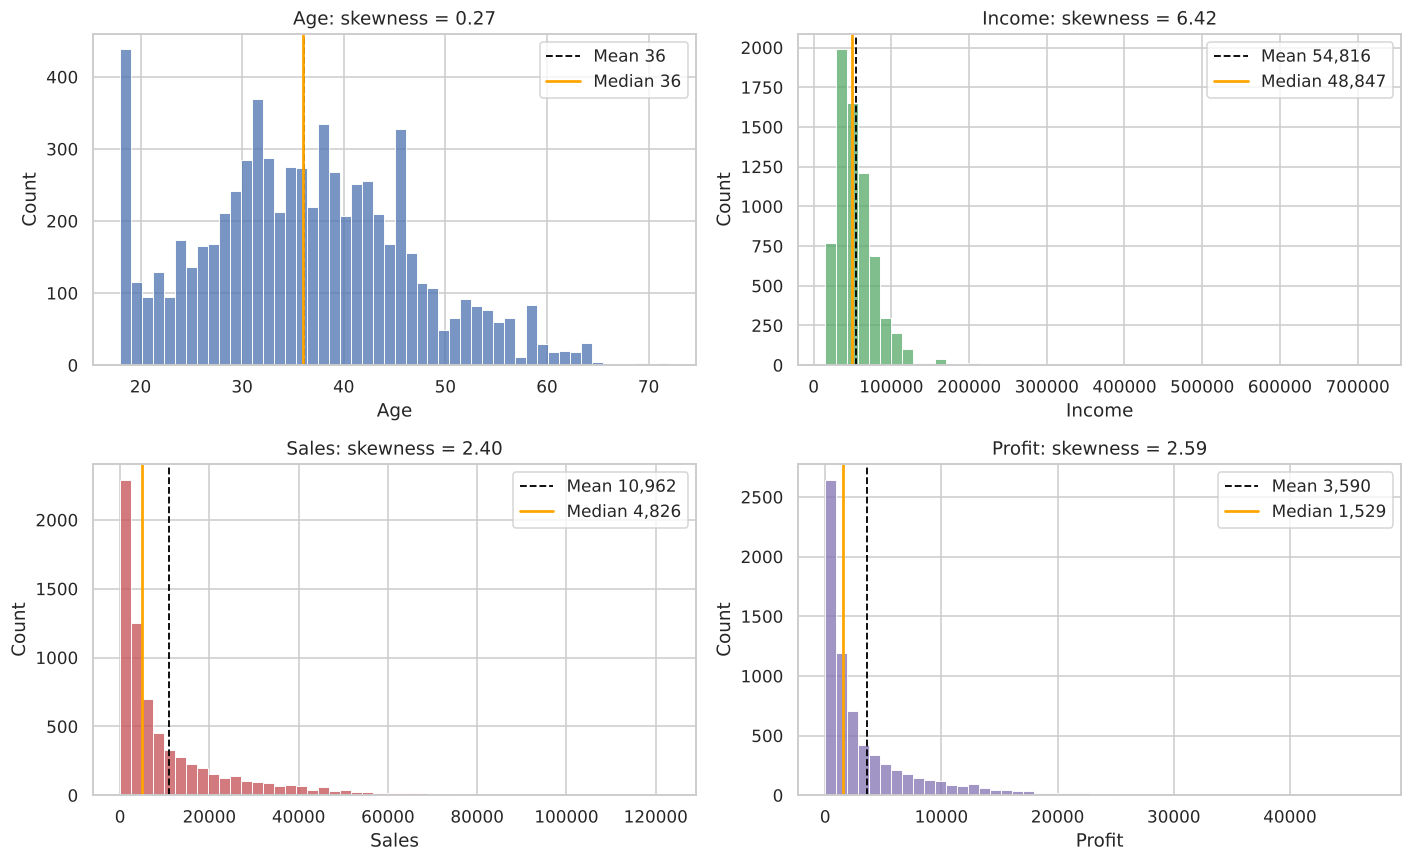

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col, color in zip(axes.ravel(), ['Age', 'Income', 'Sales', 'Profit'], ['#4C72B0', '#55A868', '#C44E52', '#8172B2']):
    sns.histplot(df[col], bins=50, color=color, ax=ax)
    ax.axvline(df[col].mean(), color='black', ls='--', lw=1.2, label=f'Mean {df[col].mean():,.0f}')
    ax.axvline(df[col].median(), color='orange', ls='-', lw=1.8, label=f'Median {df[col].median():,.0f}')
    ax.set_title(f'{col}: skewness = {df[col].skew():.2f}'); ax.legend()
plt.tight_layout()

In [20]:
def shape(sk):
    return 'roughly symmetric' if abs(sk) < 0.5 else ('right-skewed' if sk > 0 else 'left-skewed')
for c in ['Age', 'Income', 'Quantity', 'Sales', 'Profit']:
    print(f'{c:9s} skew = {df[c].skew():6.2f} -> {shape(df[c].skew()):18s} mean/median = {df[c].mean()/df[c].median():.2f}')

Age       skew =   0.27 -> roughly symmetric  mean/median = 1.00
Income    skew =   6.42 -> right-skewed       mean/median = 1.12
Quantity  skew =   0.73 -> right-skewed       mean/median = 1.00
Sales     skew =   2.40 -> right-skewed       mean/median = 2.27
Profit    skew =   2.59 -> right-skewed       mean/median = 2.35


**Reading the skew in business terms**
- **Age** is almost symmetric: the typical customer is mid-30s and there is no unusual young or old tail.
- **Income** is right-skewed: most customers earn around the median, while a small group of high earners pulls the mean above it.
- **Sales** and **Profit** are strongly right-skewed: most orders are small, but a minority of big-ticket orders (mainly Electronics and Furniture) pull the average well above the typical order. The **median** is the better description of a "normal" transaction, and the mean is what the business actually earns per order.

### 4.3 Categorical variables: frequency and proportion

--- Region ---
        count  share_%
Region                
West     1798    25.70
East     1765    25.20
South    1761    25.20
North    1676    23.90

--- Product_Category ---
                  count  share_%
Product_Category                
Electronics        1975    28.20
Grocery            1669    23.80
Clothing           1533    21.90
Furniture           979    14.00
Office Supplies     844    12.10

--- Customer_Segment ---
                  count  share_%
Customer_Segment                
Consumer           3840    54.90
Corporate          2114    30.20
Home Office        1046    14.90



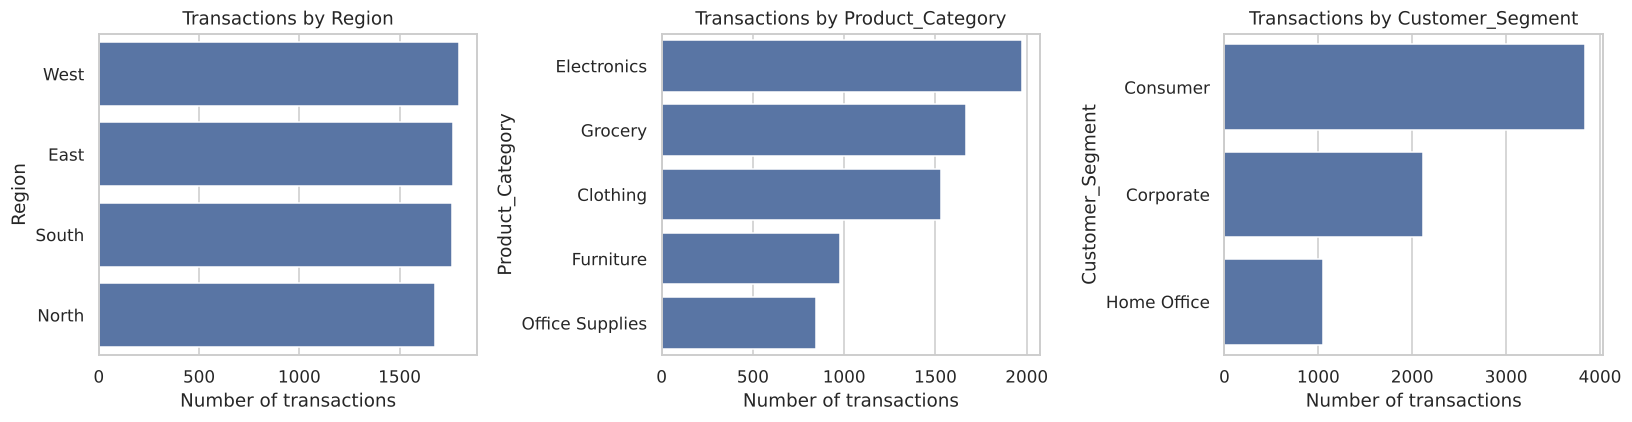

In [21]:
for c in ['Region', 'Product_Category', 'Customer_Segment']:
    t = pd.DataFrame({'count': df[c].value_counts(), 'share_%': (df[c].value_counts(normalize=True) * 100).round(1)})
    print(f'--- {c} ---'); print(t.to_string()); print()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['Region', 'Product_Category', 'Customer_Segment']):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, color='#4C72B0', ax=ax)
    ax.set_title(f'Transactions by {c}'); ax.set_xlabel('Number of transactions')
plt.tight_layout()

## 5. Outlier Detection
The **IQR rule** flags values outside `[Q1 - 1.5 x IQR, Q3 + 1.5 x IQR]`. The **Z-score rule** flags values with `|z| > 3`. Both are applied; flagged values are then judged individually.

In [22]:
def outlier_summary(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return pd.Series({'IQR_lower': lo, 'IQR_upper': hi, 'IQR_outliers': ((s < lo) | (s > hi)).sum(),
                      'IQR_%': ((s < lo) | (s > hi)).mean() * 100, 'Z>3_outliers': (z.abs() > 3).sum(),
                      'max': s.max(), 'min': s.min()})
out_tbl = pd.DataFrame({c: outlier_summary(df[c]) for c in ['Sales', 'Profit', 'Age', 'Income']}).T
out_tbl.round(2)

        IQR_lower  IQR_upper  IQR_outliers  IQR_%  Z>3_outliers        max       min
Sales  -16,604.37  32,515.17        632.00   9.03        153.00 122,950.97     28.70
Profit  -5,364.72  10,472.09        640.00   9.14        160.00  47,233.61      9.17
Age          8.00      64.00         10.00   0.14          6.00      72.00     18.00
Income  -5,769.09 108,616.22        236.00   3.37         70.00 721,081.66 15,000.00


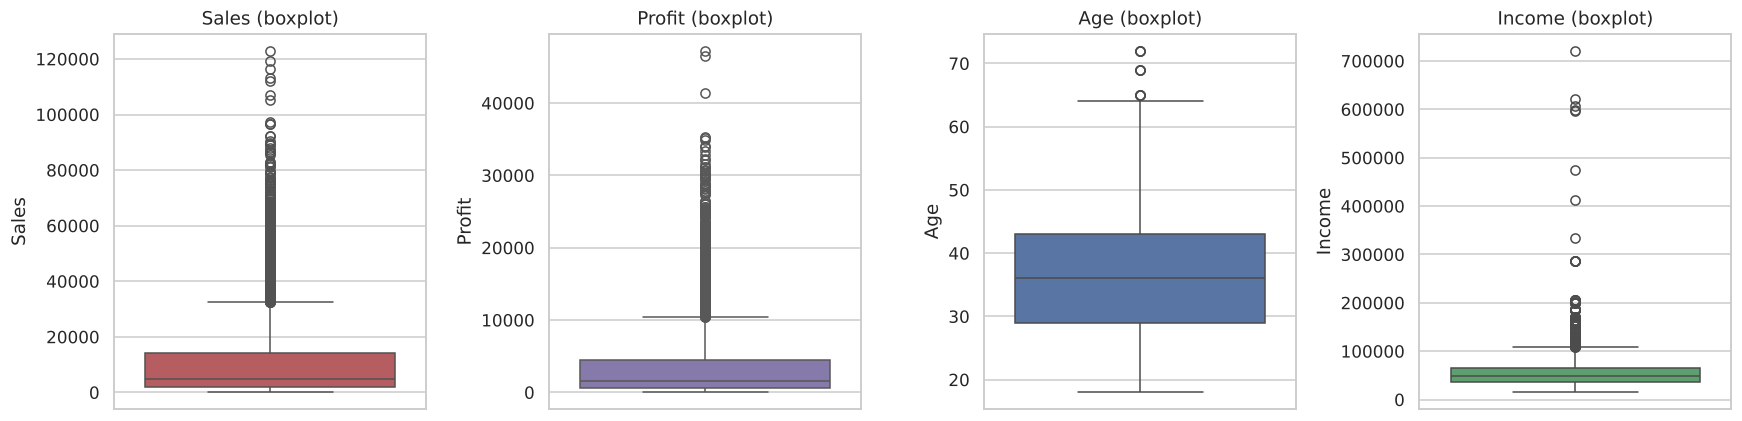

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c, color in zip(axes, ['Sales', 'Profit', 'Age', 'Income'], ['#C44E52', '#8172B2', '#4C72B0', '#55A868']):
    sns.boxplot(y=df[c], color=color, ax=ax); ax.set_title(f'{c} (boxplot)')
plt.tight_layout()

### 5.1 Are the flagged values genuine or errors?

In [24]:
q1, q3 = df.Sales.quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
s_out = df[df.Sales > hi]
print('Sales outliers:', len(s_out))
print('Category mix of Sales outliers (%):'); print((s_out.Product_Category.value_counts(normalize=True) * 100).round(1).to_string())
print('Median Unit_Price of outliers: %.0f vs %.0f for the rest' % (s_out.Unit_Price.median(), df.Unit_Price.median()))
print('Avg Quantity of outliers: %.2f vs %.2f for the rest' % (s_out.Quantity.mean(), df.Quantity.mean()))
print('Profit margin of Sales outliers: %.1f%% vs %.1f%% for the rest' % (s_out.Profit.sum()/s_out.Sales.sum()*100, df[df.Sales <= hi].Profit.sum()/df[df.Sales <= hi].Sales.sum()*100))
print('Sales formula holds for all outliers:', (((s_out.Quantity*s_out.Unit_Price*(1-s_out.Discount)) - s_out.Sales).abs() / s_out.Sales < 0.01).all())

Sales outliers: 632
Category mix of Sales outliers (%):
Product_Category
Electronics   52.50
Furniture     47.50
Median Unit_Price of outliers: 13617 vs 2261 for the rest
Avg Quantity of outliers: 4.39 vs 3.01 for the rest
Profit margin of Sales outliers: 32.8% vs 32.7% for the rest
Sales formula holds for all outliers: True


In [25]:
inc_q1, inc_q3 = df.Income.quantile([.25, .75]); inc_hi = inc_q3 + 1.5 * (inc_q3 - inc_q1)
i_out = df[df.Income > inc_hi]
print('Income above IQR fence (%.0f):' % inc_hi, len(i_out), 'rows | share %.1f%%' % (len(i_out)/len(df)*100))
print('Income values above 4 lakh :', (df.Income > 400_000).sum(), '->', sorted(df.Income[df.Income > 400_000].round(0).unique().tolist(), reverse=True))
print('Age range after cleaning  :', df.Age.min(), '-', df.Age.max(), '| IQR outliers:', outlier_summary(df.Age)['IQR_outliers'])

Income above IQR fence (108616): 236 rows | share 3.4%
Income values above 4 lakh : 7 -> [721082.0, 622290.0, 606985.0, 598321.0, 595874.0, 473562.0, 412792.0]
Age range after cleaning  : 18 - 72 | IQR outliers: 10.0


**Judgement**
| Variable | Flagged values | Verdict | Action |
|---|---|---|---|
| **Sales / Profit** | A long right tail of high-value orders | **Genuine.** They are almost entirely Electronics and Furniture, driven by high `Unit_Price`, and they obey the Sales formula and show a normal margin. Nothing is wrong with them. | Keep; report the median alongside the mean |
| **Income** | Skewed high-earner tail | **Genuine** extreme cases (income is naturally right-skewed). The one value above 10 lakh was already treated as an error in 3.4. | Keep; flagged for use in later statistics |
| **Age** | Impossible values (-12, -5, -1, 150, 180, 999) | **Data errors**, already replaced in 3.4. After cleaning, no age outliers remain. | Fixed |

## 6. Feature Engineering and Grouped Insights
### 6.1 Calculated columns

In [26]:
# 1) Profit margin of every transaction
df['Profit_Margin'] = df.Profit / df.Sales

# 2) Days between order and delivery (NaN where delivery date is missing or flagged)
df['Delivery_Days'] = (df.Delivery_Date - df.Order_Date).dt.days

# 3) Time features for trend analysis
df['Order_Year'] = df.Order_Date.dt.year
df['Order_Quarter'] = df.Order_Date.dt.quarter
df['Order_Month'] = df.Order_Date.dt.to_period('M').astype(str)

# 4) Total revenue generated by each customer across all their orders
df['Revenue_per_Customer'] = df.groupby('Customer_ID').Sales.transform('sum')

# 5) Rupee value of the discount given
df['Discount_Amount'] = df.Quantity * df.Unit_Price - df.Sales

# 6) Discount band (for grouping)
df['Discount_Band'] = pd.cut(df.Discount, [-0.001, .10, .20, .30, .40, .50], labels=['0-10%', '10-20%', '20-30%', '30-40%', '40-50%'])

# 7) Returned as a number so that its mean is the return rate
df['Returned_Flag'] = (df.Returned == 'Yes').astype(int)

df[['Transaction_ID', 'Sales', 'Profit', 'Profit_Margin', 'Delivery_Days', 'Order_Month', 'Revenue_per_Customer', 'Discount_Amount', 'Discount_Band']].head()

  Transaction_ID     Sales   Profit  Profit_Margin  Delivery_Days Order_Month  Revenue_per_Customer  Discount_Amount Discount_Band
0      TXN205933  1,811.40   606.93           0.34           6.00     2023-12              5,003.25           852.42        30-40%
1      TXN201247 23,468.33 6,331.27           0.27           4.00     2023-09             74,411.80         5,151.59        10-20%
2      TXN202714  2,587.86 1,010.03           0.39           8.00     2023-01            100,342.46           255.94         0-10%
3      TXN206797    877.75   320.97           0.37           4.00     2024-06             29,951.36           452.17        30-40%
4      TXN203937  8,328.28 2,799.81           0.34           7.00     2024-09             21,572.93         2,213.85        20-30%


### 6.2 Business questions answered with `groupby()`

**Q1. Which region has the highest average order value?**

In [27]:
q1 = df.groupby('Region').agg(orders=('Sales', 'size'), total_sales=('Sales', 'sum'), avg_order_value=('Sales', 'mean'), median_order=('Sales', 'median')).sort_values('avg_order_value', ascending=False)
q1.round(0)

        orders   total_sales  avg_order_value  median_order
Region                                                     
East      1765 20,018,192.00        11,342.00      5,030.00
West      1798 19,758,996.00        10,989.00      4,873.00
North     1676 18,063,892.00        10,778.00      4,628.00
South     1761 18,890,110.00        10,727.00      4,747.00


**Q2. Which product category earns the lowest profit margin?** (margin = total profit / total sales, so large orders weigh more)

In [28]:
q2 = df.groupby('Product_Category').agg(total_sales=('Sales', 'sum'), total_profit=('Profit', 'sum'), avg_discount=('Discount', 'mean'))
q2['profit_margin_%'] = q2.total_profit / q2.total_sales * 100
q2['share_of_sales_%'] = q2.total_sales / q2.total_sales.sum() * 100
q2.sort_values('profit_margin_%').round(1)

                   total_sales  total_profit  avg_discount  profit_margin_%  share_of_sales_%
Product_Category                                                                             
Clothing          7,781,680.40  2,521,027.80          0.20            32.40             10.10
Office Supplies   2,566,182.50    832,190.40          0.20            32.40              3.30
Grocery           2,685,875.10    874,840.20          0.20            32.60              3.50
Furniture        26,057,893.90  8,547,604.80          0.20            32.80             34.00
Electronics      37,639,557.40 12,352,219.50          0.20            32.80             49.10


**Q3. How do the three customer segments differ in order size and profitability?**

In [29]:
q3 = df.groupby('Customer_Segment').agg(orders=('Sales', 'size'), avg_order_value=('Sales', 'mean'), total_sales=('Sales', 'sum'), total_profit=('Profit', 'sum'))
q3['profit_margin_%'] = q3.total_profit / q3.total_sales * 100
q3.round(1)

                  orders  avg_order_value   total_sales  total_profit  profit_margin_%
Customer_Segment                                                                      
Consumer            3840        10,864.30 41,718,896.30 13,703,577.40            32.80
Corporate           2114        11,140.60 23,551,202.50  7,665,257.90            32.50
Home Office         1046        10,957.10 11,461,090.50  3,759,047.40            32.80


**Q4. Does a bigger discount erode profit margin?**

In [30]:
q4 = df.groupby('Discount_Band').agg(orders=('Sales', 'size'), avg_sales=('Sales', 'mean'), total_sales=('Sales', 'sum'), total_profit=('Profit', 'sum'), return_rate_pct=('Returned_Flag', lambda s: s.mean() * 100))
q4['profit_margin_%'] = q4.total_profit / q4.total_sales * 100
q4.round(1)

               orders  avg_sales   total_sales  total_profit  return_rate_pct  profit_margin_%
Discount_Band                                                                                 
0-10%            1668  13,085.50 21,826,559.40  7,190,240.60            12.90            32.90
10-20%           2329  11,541.60 26,880,486.30  8,781,322.40            11.30            32.70
20-30%           1679  10,409.70 17,477,954.90  5,704,832.50            14.30            32.60
30-40%            855   8,347.70  7,137,285.10  2,348,331.70            12.40            32.90
40-50%            469   7,268.50  3,408,903.60  1,103,155.40            11.70            32.40


**Q5. Which products or modes have the highest return rate?**

In [31]:
print('Overall return rate: %.1f%%' % (df.Returned_Flag.mean() * 100)); print()
print(df.groupby('Product_Category').Returned_Flag.mean().mul(100).round(1).sort_values(ascending=False).to_string()); print()
print(df.groupby('Delivery_Mode').Returned_Flag.mean().mul(100).round(1).sort_values(ascending=False).to_string())

Overall return rate: 12.6%

Product_Category
Clothing          13.50
Furniture         13.20
Grocery           12.50
Electronics       12.10
Office Supplies   11.50

Delivery_Mode
Same-Day   12.80
Standard   12.60
Express    12.40


**Q6. How do delivery mode, delivery time and customer rating relate?**

In [32]:
q6 = df.groupby('Delivery_Mode').agg(orders=('Sales', 'size'), avg_delivery_days=('Delivery_Days', 'mean'), avg_rating=('Customer_Rating', 'mean'), return_rate_pct=('Returned_Flag', lambda s: s.mean() * 100))
print(q6.round(2).to_string()); print()
print('Average rating by satisfaction level:')
print(df.groupby('Satisfaction_Level').Customer_Rating.mean().round(2).to_string())

               orders  avg_delivery_days  avg_rating  return_rate_pct
Delivery_Mode                                                        
Express          2055               5.63        3.11            12.41
Same-Day          696               5.77        3.12            12.79
Standard         4249               5.65        3.08            12.61

Average rating by satisfaction level:
Satisfaction_Level
High           3.86
Low            2.24
Medium         2.91
Not Provided   3.14


**Q7. How did sales change between 2023 and 2024, and which quarter is strongest?**

In [33]:
yr = df.groupby('Order_Year').agg(orders=('Sales', 'size'), total_sales=('Sales', 'sum'), total_profit=('Profit', 'sum'))
yr['growth_%'] = yr.total_sales.pct_change() * 100
print(yr.round(1).to_string()); print()
print(df.pivot_table(index='Order_Quarter', columns='Order_Year', values='Sales', aggfunc='sum').round(0).to_string())

            orders   total_sales  total_profit  growth_%
Order_Year                                              
2023          3525 38,655,639.30 12,509,509.30       NaN
2024          3475 38,075,550.00 12,618,373.40     -1.50

Order_Year            2023         2024
Order_Quarter                          
1             9,738,584.00 9,427,477.00
2             9,881,386.00 8,978,642.00
3             9,697,143.00 9,704,033.00
4             9,338,525.00 9,965,399.00


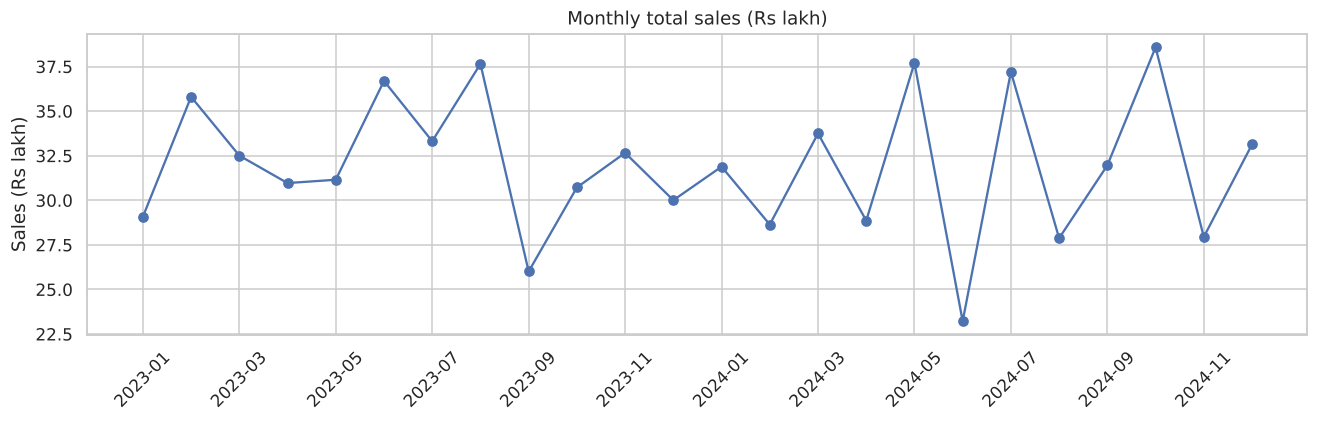

In [34]:
monthly = df.groupby('Order_Month').Sales.sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values / 1e5, marker='o', color='#4C72B0')
ax.set_title('Monthly total sales (Rs lakh)'); ax.set_ylabel('Sales (Rs lakh)')
ax.set_xticks(range(0, len(monthly), 2)); ax.set_xticklabels(monthly.index[::2], rotation=45)
plt.tight_layout()

**Q8. How concentrated is revenue?** (customers and big orders)

In [35]:
cust = df.groupby('Customer_ID').Sales.sum().sort_values(ascending=False)
top10 = cust.head(int(len(cust) * 0.10)).sum() / cust.sum() * 100
print('Unique customers:', len(cust), '| avg orders per customer: %.1f' % (len(df) / len(cust)))
print('Top 10%% of customers generate %.1f%% of sales' % top10)
big = df.Sales > hi
print('Large orders (IQR outliers) = %.1f%% of orders but %.1f%% of sales' % (big.mean() * 100, df.Sales[big].sum() / df.Sales.sum() * 100))
ef = df.Product_Category.isin(['Electronics', 'Furniture'])
print('Electronics + Furniture = %.1f%% of orders but %.1f%% of sales' % (ef.mean() * 100, df.Sales[ef].sum() / df.Sales.sum() * 100))
print('Average rating: %.2f | share of orders rated: %.1f%%' % (df.Customer_Rating.mean(), df.Rated.mean() * 100))

Unique customers: 1576 | avg orders per customer: 4.4
Top 10% of customers generate 26.7% of sales
Large orders (IQR outliers) = 9.0% of orders but 39.6% of sales
Electronics + Furniture = 42.2% of orders but 83.0% of sales
Average rating: 3.09 | share of orders rated: 94.0%


## 7. Key Findings
1. **Two categories carry the business.** Electronics and Furniture are about 42% of orders but about 83% of sales; Grocery and Office Supplies together are under 7% of sales.
2. **Order values are skewed.** The median order (about Rs 4,800) is less than half the average (about Rs 11,000) because a minority of high-ticket orders pulls the mean up. These large orders are genuine, not errors.
3. **Profitability is uniform.** Margin is about 32-33% in every category, segment and discount band. Group differences in margin are well under one percentage point.
4. **Discounts do not show up as lower margin** in this data, but higher discount bands go with smaller average orders.
5. **Regions are very similar.** East has the highest average order value (about Rs 11,300) and South the lowest (about Rs 10,700), a gap of roughly 6%.
6. **Sales are flat to slightly down.** 2024 sales are about 1.5% below 2023, with a weak Q2 2024 and a stronger Q4 2024.
7. **About 1 in 8 orders is returned** (12.6%), with little variation by category or delivery mode. Ratings match the satisfaction labels, and 6% of orders have no rating.
8. **Data quality.** The raw file had four mixed date formats, hidden duplicates (84 rows), inconsistent labels, six impossible ages and six impossible discounts. All were handled and documented above.

## 8. Export the Cleaned Dataset

In [36]:
df_out = df.drop(columns=['Order_Month']).assign(Order_Date=df.Order_Date.dt.date, Delivery_Date=df.Delivery_Date.dt.date)
df_out.to_csv('retail_customer_sales_cleaned.csv', index=False)
print('Saved retail_customer_sales_cleaned.csv ->', df_out.shape)

Saved retail_customer_sales_cleaned.csv -> (7000, 37)
